<div style="background-color: #7BAFD4; border-radius: 18px; padding: 22px 26px; margin-bottom: 18px;">
    <div style="font-family: Impact, 'Arial Black', Arial, sans-serif; font-size: 42px; font-weight: 900; letter-spacing: 2px; line-height: 1; color: white;">GEOG 592 &middot; Week 09</div>
    <div style="font-family: Arial, Helvetica, sans-serif; font-size: 22px; font-weight: 700; color: #13294B; margin-top: 8px;">Owls in the Old Growth</div>
    <div style="font-family: Arial, Helvetica, sans-serif; font-size: 16px; color: #13294B; margin-top: 6px;">Barred owl vs. northern spotted owl in Washington, Oregon and California (GBIF + Census)</div>
</div>

## The story

In class we mapped the **white mulberry** (*Morus alba*), brought to North America to feed silk moths, which now hybridizes with the native **red mulberry** (*Morus rubra*). This notebook tells a similar story with two owls.

* **Barred owl** (*Strix varia*) – originally an eastern North American species. Over the 20th century it spread west across the boreal forest of Canada and down into the Pacific Northwest.
* **Spotted owl** (*Strix occidentalis*) – the native old-growth owl of the West. The northern subspecies has been federally listed as threatened since 1990.

Barred owls are bigger, more aggressive, and eat a wider range of prey, so they push spotted owls out of their territories. The two species can also **interbreed**; their hybrids are nicknamed "sparred owls." Like the white mulberry, the newcomer is a close relative that both displaces and hybridizes with the native species.

**Region and scale:** Instead of the whole US, I zoomed in to the **counties of Washington, Oregon, and California**, where the two ranges overlap. If spotted owls are being pushed out, I expect barred owls to dominate the northern counties, with spotted owls holding on mainly in California.

**Data:** GBIF human observations from the iNaturalist research-grade dataset for 2016–2025. I used iNaturalist only, instead of every GBIF dataset, because eBird alone contributes far more barred owl records than this API approach can download in a reasonable time.

In [1]:
### Code adapted from the class mulberry notebook (mostly written with AI)
## This cell might take a few minutes to run
# https://www.gbif.org/

import time
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

species = ["Strix varia", "Strix occidentalis"]   # barred owl, spotted owl
years = "2016,2025"                                 # GBIF accepts a "min,max" year range

# iNaturalist research-grade observations. Set to None to pull every GBIF dataset (MUCH bigger).
INATURALIST = "50c9509d-22c7-4a22-a47d-8c48425ef4a7"

MAX_RECORDS = 20000   # safety limit per species; larger = longer wait

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # 1. Find the GBIF taxon identifier for the scientific name.
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if match.get("matchType") != "EXACT" or match.get("rank") != "SPECIES":
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    # 2. Define which occurrence records to request.
    #    A lat/lon box around WA, OR and CA (the spatial join later trims it to the counties).
    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "year": years,
        "decimalLatitude": "32.4,49.1",
        "decimalLongitude": "-124.9,-114.0",
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }
    if INATURALIST:
        parameters["datasetKey"] = INATURALIST

    # 3. Retrieve successive pages of records.
    species_records = []

    while True:
        response = requests.get(f"{api}/occurrence/search", params=parameters, timeout=60)
        response.raise_for_status()
        page = response.json()

        if page["count"] > MAX_RECORDS:
            raise ValueError(
                f"{name} has {page['count']:,} records. "
                "Narrow the year range or raise MAX_RECORDS."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)
    print(f"{name}: {len(species_records):,} records")

Strix varia: 4,235 records
Strix occidentalis: 451 records


In [2]:
owls = pd.DataFrame(records)
## keep only the columns I care about (reindex so a missing column doesn't break anything)
owls = owls.reindex(columns=["queried_species", "decimalLongitude", "decimalLatitude", "year"])

# Friendlier names for legends
common = {"Strix varia": "Barred owl", "Strix occidentalis": "Spotted owl"}
owls["common_name"] = owls["queried_species"].map(common)
owls.head()

,queried_species,decimalLongitude,decimalLatitude,year,common_name
0,Strix varia,-122.305631,47.263318,2025,Barred owl
1,Strix varia,-120.000053,38.930177,2025,Barred owl
2,Strix varia,-120.000269,38.930403,2025,Barred owl
3,Strix varia,-114.104052,46.835644,2025,Barred owl
4,Strix varia,-122.306887,47.651220,2025,Barred owl


<Axes: >

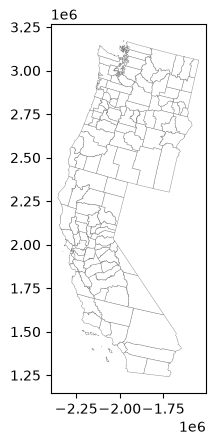

In [4]:
# getting the US census data – county level this time
import os, subprocess, requests

def download(url):
    """Download a file once into this folder and return its filename."""
    fname = url.split("/")[-1]
    if not os.path.exists(fname):
        try:
            r = requests.get(url, timeout=120)
            r.raise_for_status()
            with open(fname, "wb") as f:
                f.write(r.content)
        except requests.exceptions.SSLError:
            # fall back to the Mac's built-in curl
            subprocess.run(["curl", "-L", "-o", fname, url], check=True)
    return fname

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"   # url for census tiger data
url_county = "cb_2024_us_county_500k.zip"                    # county level

counties = gpd.read_file(download(url_0 + url_county))

state_codes = {"53": "WA", "41": "OR", "06": "CA"}   # state FIPS codes
west = counties.loc[counties["STATEFP"].isin(state_codes)].copy()
west["state"] = west["STATEFP"].map(state_codes)
west["label"] = west["NAME"] + ", " + west["state"]   # county names repeat across states, so add the state

west = west.to_crs(epsg=5070)

# State outlines (dissolve the counties) to draw on top of every map
states = west.dissolve(by="state").reset_index()

west.plot(edgecolor="gray", facecolor="white", linewidth=0.3)

In [5]:
## make a gdf from the x and y data
owl_points = gpd.GeoDataFrame(
    owls.copy(),
    geometry=gpd.points_from_xy(owls["decimalLongitude"], owls["decimalLatitude"]),
    crs="EPSG:4326"   # lat/lon
).to_crs(epsg=5070)

# keep only points inside the WA/OR/CA counties and attach the county GEOID
points_by_county = gpd.sjoin(
    owl_points,
    west[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_county["common_name"].value_counts()

common_name
Barred owl     4095
Spotted owl     424
Name: count, dtype: int64

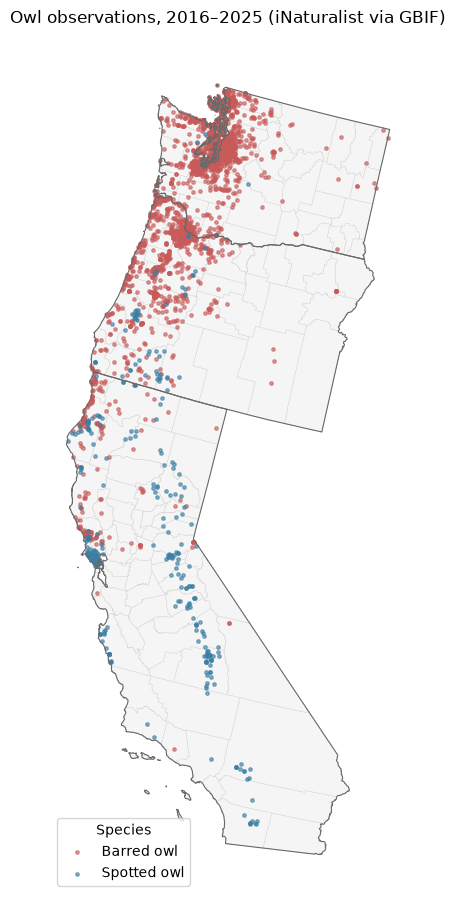

In [6]:
def pointMap(ax, counties, states, points):
    counties.plot(ax=ax, facecolor="whitesmoke", edgecolor="lightgray", linewidth=0.3)
    states.boundary.plot(ax=ax, color="dimgray", linewidth=0.8)

    # draw barred owls first so the rarer spotted owls sit on top
    colors = {"Barred owl": "#c85a5a", "Spotted owl": "#3b7fa3"}

    for name, color in colors.items():
        points.loc[points["common_name"] == name].plot(
            ax=ax, color=color, markersize=6, alpha=0.6, label=name
        )

    ax.set_title("Owl observations, 2016–2025 (iNaturalist via GBIF)")
    ax.legend(title="Species", loc="lower left")
    ax.set_axis_off()
    return ax

fig, ax = plt.subplots(figsize=(8, 11))
pointMap(ax, west, states, points_by_county)
plt.show()

In [7]:
# observations per county, one column per species
counts = (
    points_by_county
    .groupby(["GEOID", "common_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Spotted owl", "Barred owl"], fill_value=0)
)

# join counts back to every county (counties with no records get 0)
owl_map = west.merge(counts, left_on="GEOID", right_index=True, how="left")
owl_map[["Spotted owl", "Barred owl"]] = owl_map[["Spotted owl", "Barred owl"]].fillna(0)

# Which counties have the most records of each owl?
owl_map.sort_values("Barred owl", ascending=False)[["label", "Barred owl", "Spotted owl"]].head(10)

,label,Barred owl,Spotted owl
520,"King, WA",1029.0,0.0
393,"Multnomah, OR",382.0,2.0
1348,"Whatcom, WA",244.0,0.0
1628,"Washington, OR",214.0,0.0
137,"Pierce, WA",207.0,0.0
1192,"Snohomish, WA",171.0,0.0
1051,"Kitsap, WA",166.0,0.0
138,"Thurston, WA",159.0,0.0
708,"Lane, OR",138.0,2.0
516,"Skagit, WA",102.0,0.0


# Classification schemes

`mapclassify` lets geopandas group counties into classes. The class code used one nearly identical function per scheme. I combined them into a single function where the `scheme` is an argument.

These maps show **barred owl** records per county, which shows where the invader has settled.

In [8]:
%pip install mapclassify

Note: you may need to restart the kernel to use updated packages.


In [10]:
## One function that handles the continuous map AND the classified maps

def choroplethScheme(ax, gdf, states, column, scheme=None, k=5, title="", cmap="YlOrBr"):
    if scheme is None:
        # continuous color scale (no classes) -> colorbar legend
        gdf.plot(
            column=column, cmap=cmap, edgecolor="gray", linewidth=0.3,
            legend=True,
            legend_kwds={"label": f"{column} records", "shrink": 0.6},
            ax=ax
        )
    else:
        # classified color scale -> boxed legend with class ranges
        gdf.plot(
            column=column, scheme=scheme, k=k, cmap=cmap, edgecolor="gray", linewidth=0.3,
            legend=True,
            legend_kwds={"title": f"{column} records", "fontsize": 8,
                         "loc": "lower left", "fmt": "{:.0f}"},
            ax=ax
        )

    states.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=13)
    ax.set_axis_off()
    return ax

/Users/scarling/geog592-hailrod/.venv/lib/python3.13/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


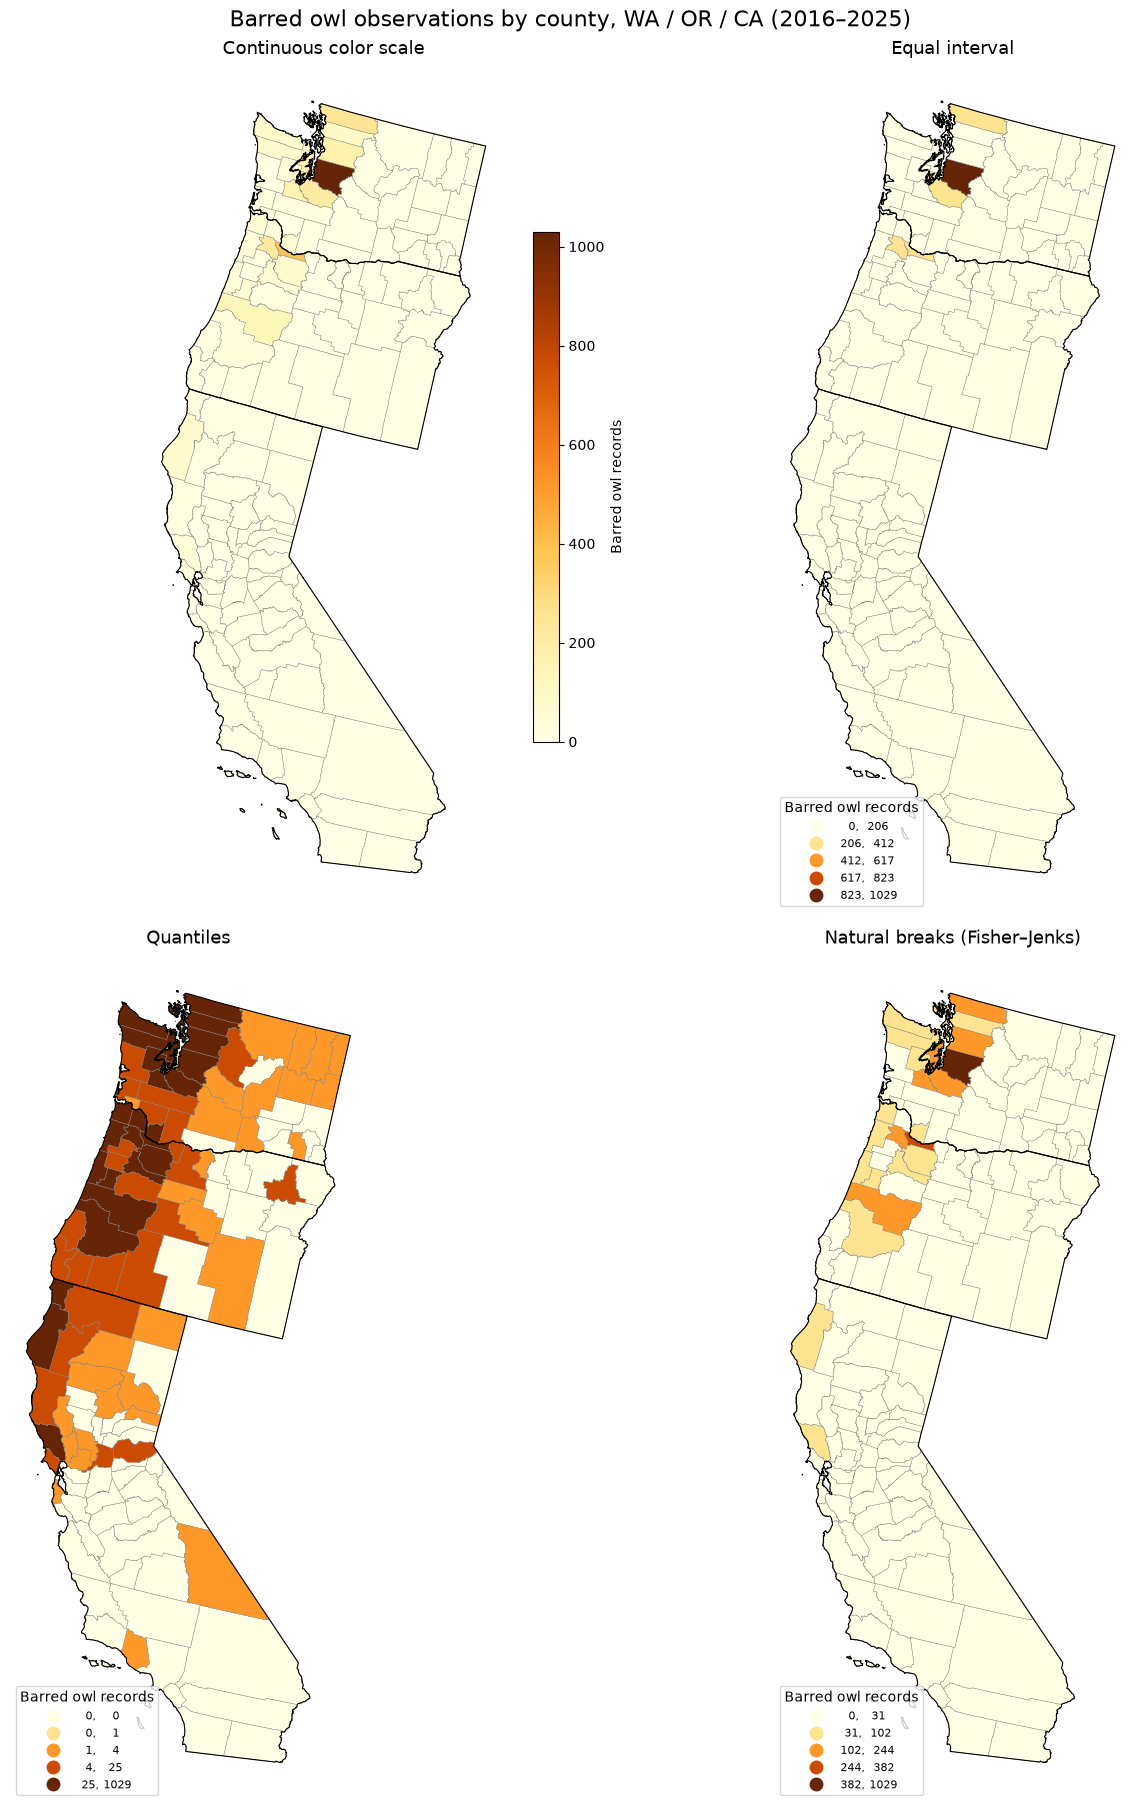

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 18), layout="constrained")

choroplethScheme(axes[0, 0], owl_map, states, "Barred owl",
                 scheme=None, title="Continuous color scale")
choroplethScheme(axes[0, 1], owl_map, states, "Barred owl",
                 scheme="equalinterval", title="Equal interval")
choroplethScheme(axes[1, 0], owl_map, states, "Barred owl",
                 scheme="quantiles", title="Quantiles")
choroplethScheme(axes[1, 1], owl_map, states, "Barred owl",
                 scheme="fisherjenks", title="Natural breaks (Fisher–Jenks)")

fig.suptitle("Barred owl observations by county, WA / OR / CA (2016–2025)", fontsize=16)

fig.savefig("owl_classification.png", dpi=300, bbox_inches="tight")
plt.show()

# Bivariate map: where do the two owls meet?

Each species is put into 3 classes (zero / lower / higher) using the median of the counties that have at least one record, the same rule as the class mulberry example. **Rows = spotted owl (native), columns = barred owl (invader).** The dark corner of the legend marks counties with many records of both species, the likely contact zone where competition and hybridization happen.

Barred owl positive-count median: 10.0
Spotted owl positive-count median: 3.0


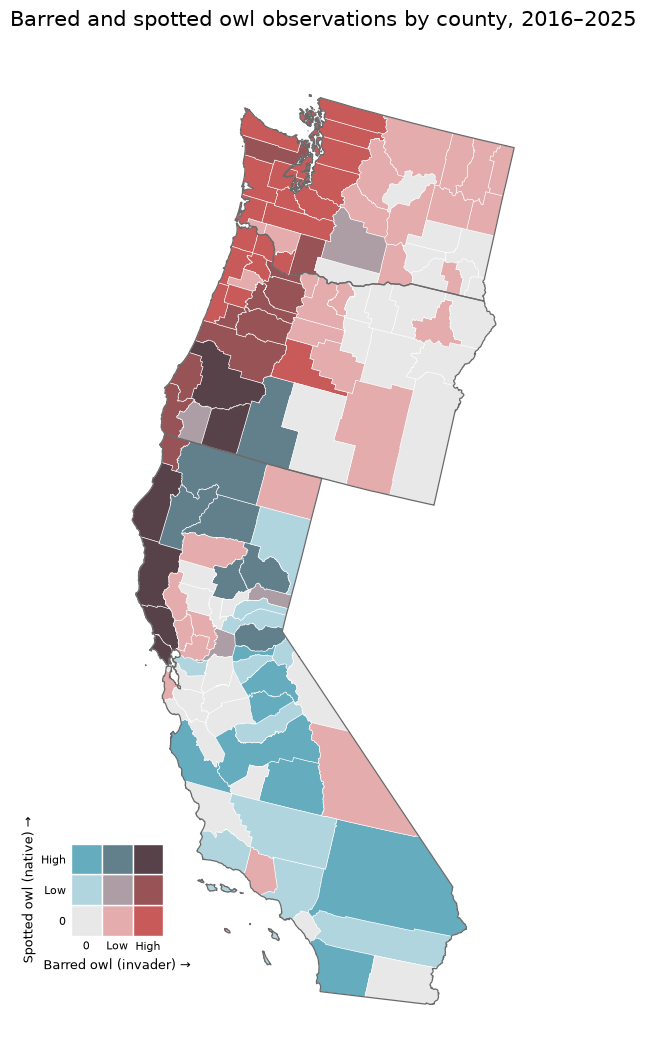

High-high contact-zone counties: Douglas, OR; Humboldt, CA; Jackson, OR; Marin, CA; Mendocino, CA; Sonoma, CA


In [18]:
## Bivariate plot code adapted from the class example (generated with AI)

bivariate = owl_map.copy()
owl_species = ["Barred owl", "Spotted owl"]

# 0 = no records, 1 = at or below the positive-count median, 2 = above it
for name in owl_species:
    values = bivariate[name]
    median = values.loc[values > 0].median()
    bivariate[name + "_class"] = np.select([values == 0, values <= median], [0, 1], default=2)
    print(name, "positive-count median:", median)

# Rows = increasing spotted owl, columns = increasing barred owl
palette = np.array([
    ["#e8e8e8", "#e4acac", "#c85a5a"],
    ["#b0d5df", "#ad9ea5", "#985356"],
    ["#64acbe", "#627f8c", "#574249"]
])

bivariate["color"] = [
    palette[spotted, barred]
    for spotted, barred in zip(bivariate["Spotted owl_class"], bivariate["Barred owl_class"])
]

fig, ax = plt.subplots(figsize=(10, 13))

bivariate.plot(color=bivariate["color"], edgecolor="white", linewidth=0.4, ax=ax)
states.boundary.plot(ax=ax, color="dimgray", linewidth=0.9)

ax.set_title("Barred and spotted owl observations by county, 2016–2025", fontsize=15)
ax.set_axis_off()

# 3 x 3 bivariate legend in the empty Pacific Ocean corner
legend_ax = ax.inset_legend_ax = ax.inset_axes([-0.10, 0.05, 0.22, 0.22])

for spotted in range(3):
    for barred in range(3):
        legend_ax.add_patch(Rectangle((barred, spotted), 1, 1,
                                      facecolor=palette[spotted, barred], edgecolor="white"))

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")
legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["0", "Low", "High"], fontsize=8)
legend_ax.set_yticklabels(["0", "Low", "High"], fontsize=8)
legend_ax.set_xlabel("Barred owl (invader) →", fontsize=9)
legend_ax.set_ylabel("Spotted owl (native) →", fontsize=9)
legend_ax.tick_params(length=0)
for spine in legend_ax.spines.values():
    spine.set_visible(False)

fig.savefig("owl_bivariate.png", dpi=300, bbox_inches="tight")
plt.show()

# Counties in the "both higher" contact zone
contact = bivariate.loc[(bivariate["Barred owl_class"] == 2) & (bivariate["Spotted owl_class"] == 2), "label"]
print("High-high contact-zone counties:", "; ".join(sorted(contact)))

# Benefits and limitations of classification schemes for species distributions

**Benefits.** Classifying counts into a few classes makes patterns readable, and choosing the scheme is a way to ask different questions. *Equal interval* keeps the real numerical spacing, so the few barred owl hotspot counties stand out. *Quantiles* put the same number of counties in each class, which shows where a species occurs at all and shows its range edges. *Natural breaks (Fisher–Jenks)* follows the clusters in the data, which helps separate core range from scattered sightings. A bivariate classification goes further and shows where two species overlap, here the zone where barred owls compete and hybridize with spotted owls.

**Limitations.** The same data can tell different stories depending on the scheme. Observation records are highly skewed, so equal interval puts almost every county in the lowest class. Quantiles can exaggerate small differences, and because so many counties have zero records, its class breaks tie or collapse. The classes also inherit every bias in the data. iNaturalist counts measure where *people* look (cities, trails, parks) as much as where owls live. Spotted owl coordinates are obscured because the species is threatened, so some points may fall in the wrong county. Large counties collect more records simply because of their size (the modifiable areal unit problem). Finally, a county's count shows presence and effort, not abundance or breeding, so the maps can't show hybrids directly.